<a href="https://colab.research.google.com/github/Johan16lindis/Redes_Neuronales_V/blob/main/Reconocimiento_Facial_Siamesas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


1. Importación de librerías

In [25]:
# Importación de librerías

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from tensorflow.keras import layers, Model
from tensorflow.keras import backend as K

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2. Carga y exploración del conjunto de datos

In [26]:
# Ruta del dataset en Google Drive

DATASET_PATH = "/content/drive/MyDrive/Redes_Neuronales_V/dataset"

# Verificar las carpetas disponibles

personas = os.listdir(DATASET_PATH)

print("Identidades encontradas:")

for persona in personas:
    ruta = os.path.join(DATASET_PATH, persona)

    if os.path.isdir(ruta):
        cantidad = len([
            f for f in os.listdir(ruta)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])

        print(persona, ":", cantidad, "imágenes")

Identidades encontradas:
persona_01 : 15 imágenes
persona_02 : 15 imágenes
persona_03 : 15 imágenes


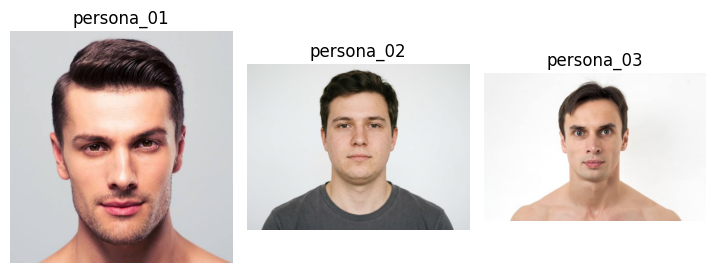

In [28]:
plt.figure(figsize=(12, 6))

for i, persona in enumerate(personas[:5]):

    ruta_persona = os.path.join(DATASET_PATH, persona)

    imagenes = [
        f for f in os.listdir(ruta_persona)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    if imagenes:
        imagen = Image.open(
            os.path.join(ruta_persona, imagenes[0])
        )

        plt.subplot(1, 5, i + 1)
        plt.imshow(imagen)
        plt.title(persona)
        plt.axis("off")

plt.tight_layout()
plt.show()

3. Preprocesamiento de imágenes

In [29]:
# Configuración de imágenes

IMG_SIZE = 128

# Detector facial de OpenCV

import cv2

cascade_path = cv2.data.haarcascades + \
    "haarcascade_frontalface_default.xml"

face_detector = cv2.CascadeClassifier(cascade_path)


def preprocess_image(image_path):

    image = cv2.imread(str(image_path))

    if image is None:
        return None

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    faces = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(40, 40)
    )

    # Recortar el rostro más grande si se detecta

    if len(faces) > 0:

        x, y, w, h = max(
            faces,
            key=lambda face: face[2] * face[3]
        )

        image = image[y:y+h, x:x+w]

    # Convertir a RGB

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # Redimensionar

    image = cv2.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )

    # Normalizar

    image = image.astype("float32") / 255.0

    return image


print("Función de preprocesamiento creada correctamente.")

Función de preprocesamiento creada correctamente.


In [30]:
# Cargar y procesar el dataset

images = []
labels = []

for persona in sorted(os.listdir(DATASET_PATH)):

    ruta_persona = os.path.join(
        DATASET_PATH,
        persona
    )

    if not os.path.isdir(ruta_persona):
        continue

    for archivo in os.listdir(ruta_persona):

        if archivo.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        ):

            ruta_imagen = os.path.join(
                ruta_persona,
                archivo
            )

            imagen = preprocess_image(ruta_imagen)

            if imagen is not None:

                images.append(imagen)
                labels.append(persona)


X = np.array(images, dtype=np.float32)
y = np.array(labels)

print("Dimensiones de las imágenes:", X.shape)
print("Cantidad total de imágenes:", len(X))
print("Identidades:", np.unique(y))

Dimensiones de las imágenes: (45, 128, 128, 3)
Cantidad total de imágenes: 45
Identidades: ['persona_01' 'persona_02' 'persona_03']


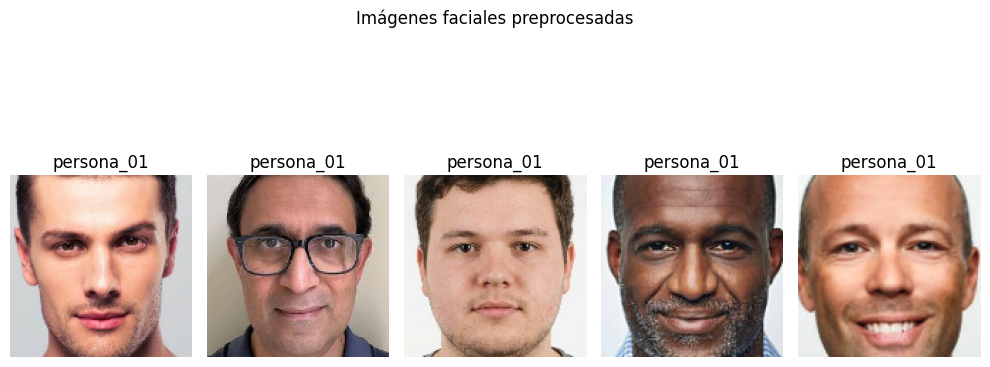

In [31]:
plt.figure(figsize=(10, 5))

for i in range(min(5, len(X))):

    plt.subplot(1, 5, i + 1)

    plt.imshow(X[i])
    plt.title(y[i])
    plt.axis("off")

plt.suptitle("Imágenes faciales preprocesadas")
plt.tight_layout()
plt.show()

4. División del conjunto de datos

In [32]:
# Primera división: entrenamiento + validación / prueba

indices = np.arange(len(X))

train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Segunda división: entrenamiento / validación

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.20,
    random_state=42,
    stratify=y[train_val_idx]
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (28, 128, 128, 3)
Validación: (8, 128, 128, 3)
Prueba: (9, 128, 128, 3)


5. Construcción de la arquitectura siamesa

In [33]:
# Arquitectura CNN para generar embeddings

def build_embedding_model():

    inputs = layers.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    x = layers.RandomFlip("horizontal")(inputs)

    x = layers.RandomRotation(0.05)(x)

    x = layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    )(x)

    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    )(x)

    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    )(x)

    x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        128,
        activation=None
    )(x)

    # Normalización del embedding

    outputs = layers.Lambda(
        lambda t: tf.math.l2_normalize(t, axis=1)
    )(x)

    return Model(
        inputs,
        outputs,
        name="Embedding_CNN"
    )


embedding_model = build_embedding_model()

embedding_model.summary()

Model: "Embedding_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 128)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,760 (428.75 KB)

 Trainable params: 109,760 (428.75 KB)

 Non-trainable params: 0 (0.00 B)

6. Implementación de Triplet Loss

In [34]:
# Función Triplet Loss

def triplet_loss(anchor, positive, negative):

    distance_positive = tf.reduce_sum(
        tf.square(anchor - positive),
        axis=1
    )

    distance_negative = tf.reduce_sum(
        tf.square(anchor - negative),
        axis=1
    )

    margin = 0.5

    loss = tf.maximum(
        distance_positive -
        distance_negative +
        margin,
        0.0
    )

    return tf.reduce_mean(loss)


print("Función Triplet Loss implementada correctamente.")

Función Triplet Loss implementada correctamente.


7. Preparación de tripletas para entrenamiento

In [35]:
# Preparación de tripletas

def create_triplets(images, labels, batch_size=32):

    unique_labels = np.unique(labels)

    label_indices = {
        label: np.where(labels == label)[0]
        for label in unique_labels
    }

    anchors = []
    positives = []
    negatives = []

    for _ in range(batch_size):

        # Seleccionar identidad del Anchor

        anchor_label = random.choice(unique_labels)

        positive_indices = label_indices[anchor_label]

        # Seleccionar dos imágenes distintas
        # de la misma identidad

        anchor_idx, positive_idx = np.random.choice(
            positive_indices,
            size=2,
            replace=False
        )

        # Seleccionar una identidad diferente

        negative_label = random.choice([
            label for label in unique_labels
            if label != anchor_label
        ])

        negative_idx = random.choice(
            label_indices[negative_label]
        )

        anchors.append(images[anchor_idx])
        positives.append(images[positive_idx])
        negatives.append(images[negative_idx])

    return (
        np.array(anchors, dtype=np.float32),
        np.array(positives, dtype=np.float32),
        np.array(negatives, dtype=np.float32)
    )


print("Generador de tripletas creado correctamente.")

Generador de tripletas creado correctamente.


In [37]:
# Configuración del entrenamiento

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001
)

@tf.function
def train_step(anchor, positive, negative):

    with tf.GradientTape() as tape:

        emb_anchor = embedding_model(
            anchor,
            training=True
        )

        emb_positive = embedding_model(
            positive,
            training=True
        )

        emb_negative = embedding_model(
            negative,
            training=True
        )

        loss = triplet_loss(
            emb_anchor,
            emb_positive,
            emb_negative
        )

    gradients = tape.gradient(
        loss,
        embedding_model.trainable_variables
    )

    optimizer.apply_gradients(
        zip(
            gradients,
            embedding_model.trainable_variables
        )
    )

    return loss

In [38]:
# Entrenamiento del modelo

EPOCHS = 20
STEPS_PER_EPOCH = 50
BATCH_SIZE = 32

history = []

for epoch in range(EPOCHS):

    epoch_losses = []

    for step in range(STEPS_PER_EPOCH):

        anchor, positive, negative = create_triplets(
            X_train,
            y_train,
            BATCH_SIZE
        )

        loss = train_step(
            anchor,
            positive,
            negative
        )

        epoch_losses.append(float(loss.numpy()))

    average_loss = np.mean(epoch_losses)

    history.append(average_loss)

    print(
        f"Época {epoch + 1}/{EPOCHS} "
        f"- Loss: {average_loss:.4f}"
    )

Época 1/20 - Loss: 0.4859
Época 2/20 - Loss: 0.4845
Época 3/20 - Loss: 0.4533
Época 4/20 - Loss: 0.4388
Época 5/20 - Loss: 0.4121
Época 6/20 - Loss: 0.3979
Época 7/20 - Loss: 0.3293
Época 8/20 - Loss: 0.3108
Época 9/20 - Loss: 0.2633
Época 10/20 - Loss: 0.2610
Época 11/20 - Loss: 0.1864
Época 12/20 - Loss: 0.1343
Época 13/20 - Loss: 0.1024
Época 14/20 - Loss: 0.0791
Época 15/20 - Loss: 0.0476
Época 16/20 - Loss: 0.0238
Época 17/20 - Loss: 0.0201
Época 18/20 - Loss: 0.0067
Época 19/20 - Loss: 0.0055
Época 20/20 - Loss: 0.0019


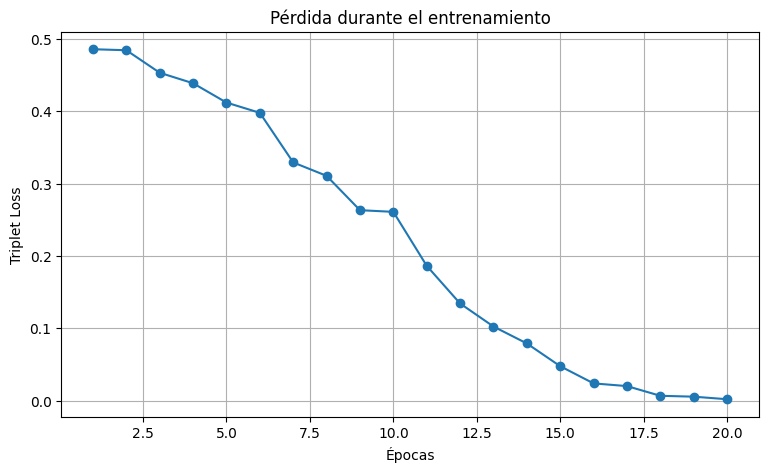

In [39]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, EPOCHS + 1),
    history,
    marker="o"
)

plt.title("Pérdida durante el entrenamiento")
plt.xlabel("Épocas")
plt.ylabel("Triplet Loss")

plt.grid(True)
plt.show()

8. Comparación de embeddings faciales

In [40]:
# Comparación de embeddings

def calculate_distance(image1, image2):

    embedding1 = embedding_model.predict(
        np.expand_dims(image1, axis=0),
        verbose=0
    )

    embedding2 = embedding_model.predict(
        np.expand_dims(image2, axis=0),
        verbose=0
    )

    distance = np.linalg.norm(
        embedding1 - embedding2
    )

    return float(distance)


print("Función de comparación creada correctamente.")

Función de comparación creada correctamente.


In [41]:
# Generación de pares para evaluación

def create_pairs(images, labels, n_pairs=200):

    unique_labels = np.unique(labels)

    label_indices = {
        label: np.where(labels == label)[0]
        for label in unique_labels
    }

    pairs = []
    targets = []

    for _ in range(n_pairs // 2):

        # Par positivo

        label = random.choice(unique_labels)

        idx1, idx2 = np.random.choice(
            label_indices[label],
            2,
            replace=False
        )

        pairs.append((images[idx1], images[idx2]))
        targets.append(1)

        # Par negativo

        label1, label2 = np.random.choice(
            unique_labels,
            2,
            replace=False
        )

        idx1 = random.choice(label_indices[label1])
        idx2 = random.choice(label_indices[label2])

        pairs.append((images[idx1], images[idx2]))
        targets.append(0)

    return pairs, np.array(targets)


val_pairs, y_val_pairs = create_pairs(
    X_val,
    y_val,
    n_pairs=200
)

test_pairs, y_test_pairs = create_pairs(
    X_test,
    y_test,
    n_pairs=200
)

print("Pares de validación:", len(val_pairs))
print("Pares de prueba:", len(test_pairs))

Pares de validación: 200
Pares de prueba: 200


In [42]:
# Obtener distancias de validación y prueba

def get_distances(pairs):

    distances = []

    for image1, image2 in pairs:

        distance = calculate_distance(
            image1,
            image2
        )

        distances.append(distance)

    return np.array(distances)


val_distances = get_distances(val_pairs)
test_distances = get_distances(test_pairs)

print("Distancias calculadas correctamente.")

Distancias calculadas correctamente.


In [43]:
# Selección del umbral mediante curva ROC

fpr, tpr, thresholds = roc_curve(
    y_val_pairs,
    -val_distances
)

best_index = np.argmax(tpr - fpr)

THRESHOLD = -thresholds[best_index]

print("Umbral seleccionado:", THRESHOLD)

Umbral seleccionado: 1.000124216079712


In [44]:
# Predicciones finales

y_pred = (
    test_distances <= THRESHOLD
).astype(int)

# Métricas de evaluación

accuracy = accuracy_score(
    y_test_pairs,
    y_pred
)

precision = precision_score(
    y_test_pairs,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test_pairs,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test_pairs,
    y_pred,
    zero_division=0
)

print("RESULTADOS DE EVALUACIÓN")
print("-----------------------")

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

RESULTADOS DE EVALUACIÓN
-----------------------
Accuracy: 0.46
Precision: 0.4375
Recall: 0.28
F1-Score: 0.3415


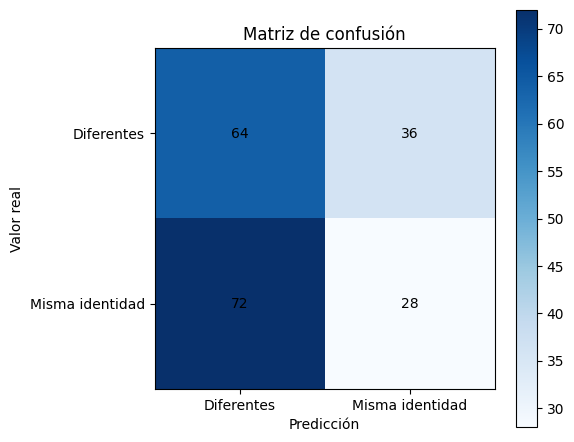

In [45]:
# Matriz de confusión

cm = confusion_matrix(
    y_test_pairs,
    y_pred
)

plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap="Blues")

plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")

plt.xticks(
    [0, 1],
    ["Diferentes", "Misma identidad"]
)

plt.yticks(
    [0, 1],
    ["Diferentes", "Misma identidad"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

9. Demostración de verificación facial

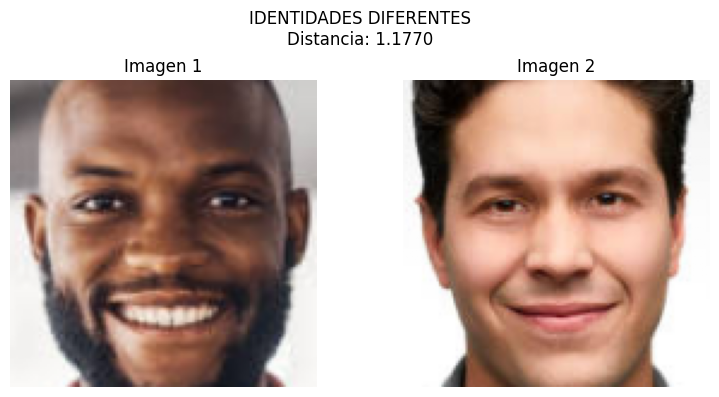

Resultado: IDENTIDADES DIFERENTES
Distancia: 1.177


In [46]:
# Función para comparar dos imágenes

def compare_faces(index1, index2):

    image1 = X_test[index1]
    image2 = X_test[index2]

    distance = calculate_distance(
        image1,
        image2
    )

    prediction = (
        "MISMA IDENTIDAD"
        if distance <= THRESHOLD
        else "IDENTIDADES DIFERENTES"
    )

    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image1)
    plt.title("Imagen 1")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(image2)
    plt.title("Imagen 2")
    plt.axis("off")

    plt.suptitle(
        f"{prediction}\nDistancia: {distance:.4f}"
    )

    plt.tight_layout()
    plt.show()

    print("Resultado:", prediction)
    print("Distancia:", round(distance, 4))


# Ejemplo de comparación

compare_faces(0, 1)

10. Exportación del modelo

In [49]:
# Guardar modelo entrenado

MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Redes_Neuronales_V/modelo_siamesa.keras"
)

embedding_model.save(MODEL_PATH)

print("Modelo guardado correctamente.")

Modelo guardado correctamente.
